# 04 xgboost

trains xgboost on the shared features from notebook 03 and scores it in the same 25 week backtest as the baselines. the model is refitted at every cutoff using only the data before it.

settings: 300 trees, learning rate 0.05, depth 6, no tuning. the target is raw sales and forecasts are clipped at 0.


## Setup (Imports and Loading Data)

In [11]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

import sys
sys.path.append('../src')

from load_clean_data import load_clean_data
from backtest import get_cutoffs, split_data_by_cutoff, run_backtest
from baselines import add_all_baselines
from evaluation import score_forecasts
from features import build_features, FEATURE_COLUMNS
from models import add_xgb_forecast, XGB_PARAMS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
df = load_clean_data()
df_with_features = build_features(df)

## Train Test Split

In [13]:
train, test = split_data_by_cutoff(df_with_features, '2015-02-02', 7)

## Run XGB (One Cutoff)

smoke test on one cutoff (2015-02-02) before running all 25. the fit takes about 30 seconds.

In [14]:
results = add_xgb_forecast(train, test, '2015-02-02')

In [15]:
print(len(results))
print(results['xgboost_forecast'].describe())

7805
count     7805.000000
mean      6810.472168
std       3945.342041
min          0.000000
25%       4929.944336
50%       6953.083008
75%       9048.419922
max      27231.585938
Name: xgboost_forecast, dtype: float64


### Compare against baselines

In [16]:
results = add_all_baselines(train, results, '2015-02-02')

scores = score_forecasts(results, ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgboost_forecast'])

In [17]:
scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
xgboost_forecast,1053.18,688.49,10.63%
avg_28d_baseline,1128.94,711.88,10.99%
naive_baseline,1098.63,711.96,10.99%
avg_all_baseline,1261.37,887.79,13.71%


finding: xgboost is best at this cutoff, but only just (10.63% against 10.99% for the 28 day average and the naive baseline). this is a calm week, so a small gap is expected. the full backtest is the real test.

## Run XGB (All Cutoffs)

all 25 cutoffs, the same as notebook 02. the baselines and xgboost are scored on the same 195,125 rows. the backtest takes a while, so the result is saved and reloaded when FORECAST is False.

In [18]:
def forecast_all(train, test, cutoff):
    with_baselines = add_all_baselines(train, test, cutoff)
    with_xgb = add_xgb_forecast(train, with_baselines, cutoff)
    return with_xgb

In [19]:
FORECAST = False

if FORECAST:
    cutoffs = get_cutoffs(df['Date'].max(), 7)
    bt = run_backtest(df_with_features, cutoffs, 7, forecast_all)

    bt.to_csv('../results/backtests/xgb_baselines_backtest.csv', index=False)

else: 
    bt = pd.read_csv('../results/backtests/xgb_baselines_backtest.csv', parse_dates=['Date', 'cutoff'], low_memory=False)

In [20]:
forecasts = ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgboost_forecast']

scores = score_forecasts(bt, forecasts)
scores.to_csv('../results/xgb_scores.csv', index=False)

model_names = {
    'naive_baseline': 'Naive Baseline',
    'avg_28d_baseline': '28-Day Average Baseline',
    'avg_all_baseline': 'Full History Average Baseline',
    'xgboost_forecast': 'XGBoost Forecast'
}

relabelled_scores = scores.copy()

relabelled_scores['Model'] = relabelled_scores['Model'].replace(model_names)

relabelled_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
XGBoost Forecast,1001.30,604.95,10.33%
Full History Average Baseline,2029.48,1261.49,21.53%
28-Day Average Baseline,2127.55,1326.10,22.63%
Naive Baseline,3206.68,2112.59,36.06%


finding: xgboost has the lowest error at 10.33% WAPE, about half of the best baseline (21.53%). RMSE also halves (1001 against 2029).

caveat: the baselines only use past sales, while xgboost also sees Promo and the holiday flags. so this does not show that xgboost as an algorithm is twice as good. the deep learning models get the same features, so the comparison between them is fair.

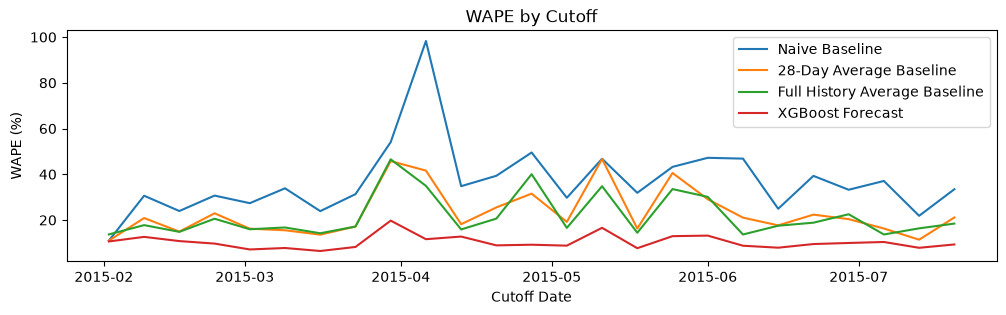

In [21]:
scores_by_cutoff = score_forecasts(bt, forecasts, by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

plt.figure(figsize=(12, 3))

for model in forecasts:
    plt.plot(pivotted.index, pivotted[model], label=model_names[model])

plt.title('WAPE by Cutoff')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

finding: xgboost has the lowest error in every one of the 25 weeks and is much steadier than the baselines. the holiday weeks around 30 mar and mid may are still its worst, but the spikes are much smaller (about 20% against 45% to 98% for the baselines).

## Feature Importance

importance from one fit at the 2015-07-20 cutoff, using gain (how much each feature reduced the error). features that carry similar information share the credit, so this shows what the model used, not what causes sales.

In [22]:
importance_train, importance_test = split_data_by_cutoff(df_with_features, '2015-07-20', 7)

model = xgb.XGBRegressor(**XGB_PARAMS)

_ = model.fit(importance_train[FEATURE_COLUMNS], importance_train['Sales'])

<Axes: title={'center': 'Feature Importances'}, xlabel='Importance (Gain)', ylabel='Features'>

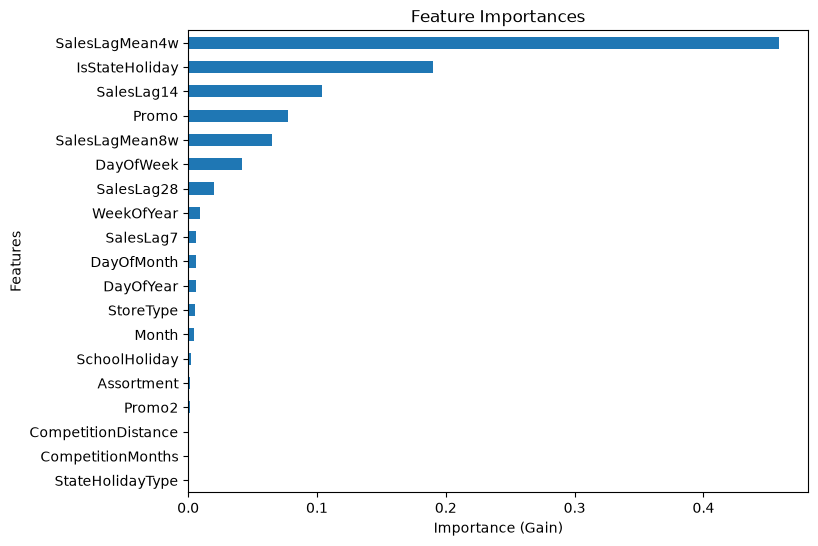

In [23]:
feature_importances = pd.Series(model.feature_importances_, index=FEATURE_COLUMNS).sort_values()

feature_importances.plot(kind='barh', figsize=(8, 6), xlabel='Importance (Gain)', ylabel='Features', title='Feature Importances')

finding: the sales history features carry most of the importance (about 65%, led by the 4 week same weekday average). IsStateHoliday is second, then Promo. the competition features, Promo2, Assortment and StateHolidayType add almost nothing, probably because the sales history already reflects each store's level and IsStateHoliday carries the holiday information.

### Why IsStateHoliday Matters

check: how different are state holidays from other days? sundays are left out, since stores are closed on sundays anyway.

In [24]:
non_sunday = df_with_features[df_with_features['DayOfWeek'] != 7]

non_sunday.groupby('IsStateHoliday')['Sales'].agg(
    mean_sales='mean',
    share_zero=lambda s: (s == 0).mean()
)

,mean_sales,share_zero
IsStateHoliday,,
0,6932.826235,0.002258
1,260.430728,0.970463


finding: stores are closed on state holidays. 97.0% of store days on a holiday have zero sales, against 0.2% on other non-sunday days. the baselines predict a normal day on holidays, which is why they spike so badly at easter. xgboost has the flag and does not.